# Lab - EDA Univariate Analysis: Diving into Amazon UK Product Insights

**Objective**: explore the product listing dynamics on Amazon UK to extract actionable business insights on product positioning, pricing strategies and inventory management.

**Dataset**: [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)


In [1]:
## Setup


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data/amz_uk_price_prediction_dataset.csv")

In [2]:
df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [3]:
print("df Shape:", df.shape)
df.info()
print("df Isna:\n", df.isna().sum())
print("df Duplicated:", df.duplicated().sum())


df Shape: (2443651, 9)
<class 'pandas.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               str    
 2   title              str    
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           str    
dtypes: bool(1), float64(2), int64(3), str(3)
memory usage: 495.8 MB
df Isna:
 uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64
df Duplicated: 0


---
## Part 1: Understanding Product Categories

**Business Question**: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?


### 1. Frequency Tables
- Generate a frequency table for the product `category`.
- Which are the top 5 most listed product categories?

In [4]:
freq_table = pd.DataFrame({
    "count": df["category"].value_counts(),
    "percentage": df["category"].value_counts(normalize=True).mul(100).round(2)
})

print("number of categories:", df["category"].nunique())
freq_table.head(10)

number of categories: 296


,count,percentage
category,,
Sports & Outdoors,836265,34.22
Beauty,19312,0.79
"Handmade Clothing, Shoes & Accessories",19229,0.79
Bath & Body,19092,0.78
Birthday Gifts,18978,0.78
Manicure & Pedicure Products,18940,0.78
Skin Care,18769,0.77
Make-up,18756,0.77
Hair Care,18735,0.77


In [5]:
top5 = freq_table.head(5)
top5

,count,percentage
category,,
Sports & Outdoors,836265,34.22
Beauty,19312,0.79
"Handmade Clothing, Shoes & Accessories",19229,0.79
Bath & Body,19092,0.78
Birthday Gifts,18978,0.78


### 2. Visualizations
- Display the distribution of products across different categories using a bar chart. *If you face problems understanding the chart, do it for a subset of top categories.*
- For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

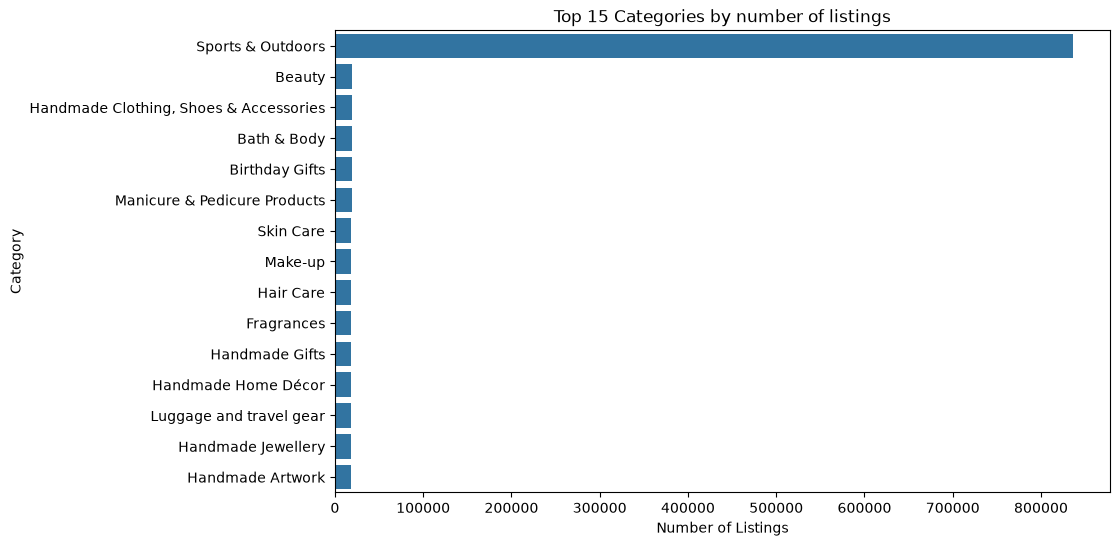

In [6]:
top15 = freq_table.head(15)

plt.figure(figsize=(10, 6))
sns.barplot(x=top15["count"], y=top15.index)
plt.title("Top 15 Categories by number of listings")
plt.xlabel("Number of Listings")
plt.ylabel("Category")
plt.show()

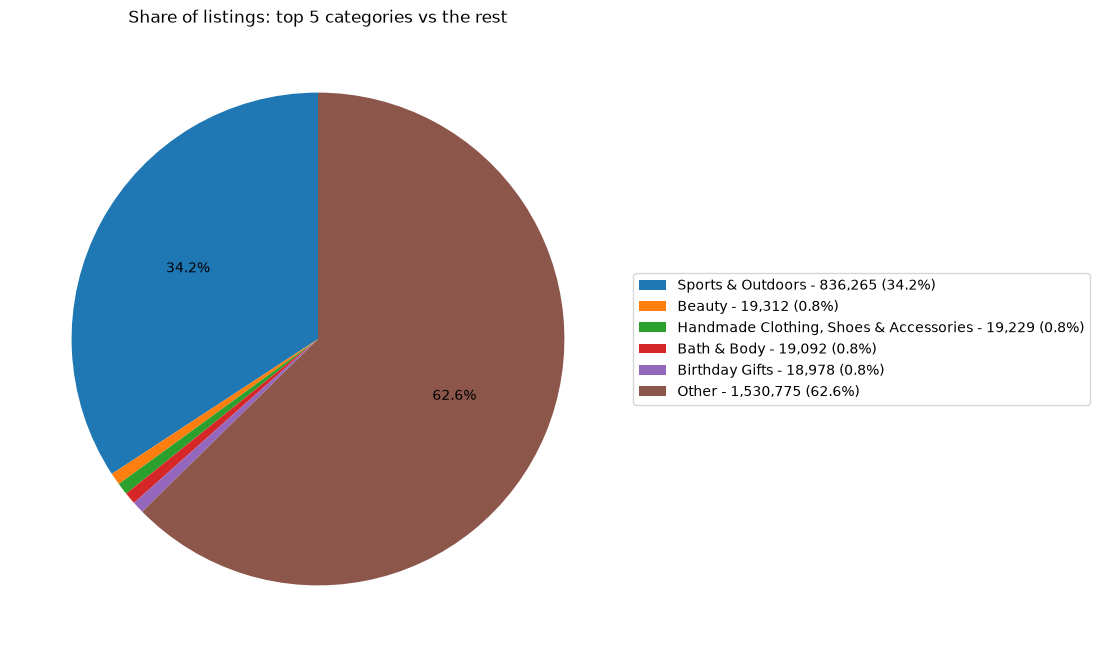

In [7]:
pie_data = df["category"].value_counts().head(5)
pie_data["Other"] = len(df) - pie_data.sum()

# one label per slice: "name - count (percentage)"
legend_labels = [
    f"{name} - {value:,} ({value / len(df) * 100:.1f}%)"
    for name, value in pie_data.items()
]

plt.figure(figsize=(9, 8))
plt.pie(pie_data, autopct=lambda p: f"{p:.1f}%" if p > 3 else "", startangle=90)
plt.legend(legend_labels, loc="center left", bbox_to_anchor=(1, 0.5))
plt.title("Share of listings: top 5 categories vs the rest")
plt.show()


### Part 1 - Findings
- **Top 5 categories**: *Sports & Outdoors* (836,265 listings), *Beauty* (19,312), *Handmade Clothing, Shoes & Accessories* (19,229), *Bath & Body* (19,092) and *Birthday Gifts* (18,978).
- **One category dominates**: *Sports & Outdoors* holds 34.2% of all listings, about 43 times more than the second one. Every other category weighs less than 1%, so the market is a very long tail of 296 categories.
- **Business reading**: competition for visibility is highest in Sports & Outdoors, while niche categories have few listings and may be easier to enter.
- **Charts**: the bar chart is much easier to read. In the pie chart the four small slices are indistinguishable, even after grouping everything else as "Other".


---
## Part 2: Delving into Product Pricing

**Business Question**: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

### 1. Measures of Centrality
- Calculate the mean, median, and mode for the `price` of products.
- What's the average price point of products listed? How does this compare with the most common price point (mode)?

In [8]:
price_mean = df["price"].mean()
price_median = df["price"].median()
price_mode = df["price"].mode()[0]

print(f"Mean:   £{price_mean:.2f}")
print(f"Median: £{price_median:.2f}")
print(f"Mode:   £{price_mode:.2f}")

df["price"].value_counts().head(10)


Mean:   £89.24
Median: £19.09
Mode:   £9.99


price
9.99     48922
12.99    38823
8.99     34058
7.99     33632
14.99    32570
6.99     31948
5.99     27818
19.99    27436
11.99    25488
10.99    25172
Name: count, dtype: int64

### 2. Measures of Dispersion
- Determine the variance, standard deviation, range, and interquartile range for product `price`.
- How varied are the product prices? Are there any indicators of a significant spread in prices?

In [9]:
price_var = df["price"].var()
price_std = df["price"].std()
price_range = df["price"].max() - df["price"].min()
q1 = df["price"].quantile(0.25)
q3 = df["price"].quantile(0.75)
price_iqr = q3 - q1

print(f"Variance: {price_var:,.2f}")
print(f"Std dev:  £{price_std:.2f}")
print(f"Range:    £{price_range:,.2f}")
print(f"IQR:      £{price_iqr:.2f} (Q1 £{q1:.2f}, Q3 £{q3:.2f})")
print(f"Coefficient of variation: {price_std / price_mean:.2f}")

df["price"].quantile([0.5, 0.9, 0.95, 0.99, 0.999])


Variance: 119,445.49
Std dev:  £345.61
Range:    £100,000.00
IQR:      £36.00 (Q1 £9.99, Q3 £45.99)
Coefficient of variation: 3.87


0.500      19.09
0.900     149.99
0.950     349.50
0.990    1408.82
0.999    4404.99
Name: price, dtype: float64

### 3. Visualizations
- Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. *If its hard to read these diagrams, think why this is, and explain how it could be solved.*
- Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing.

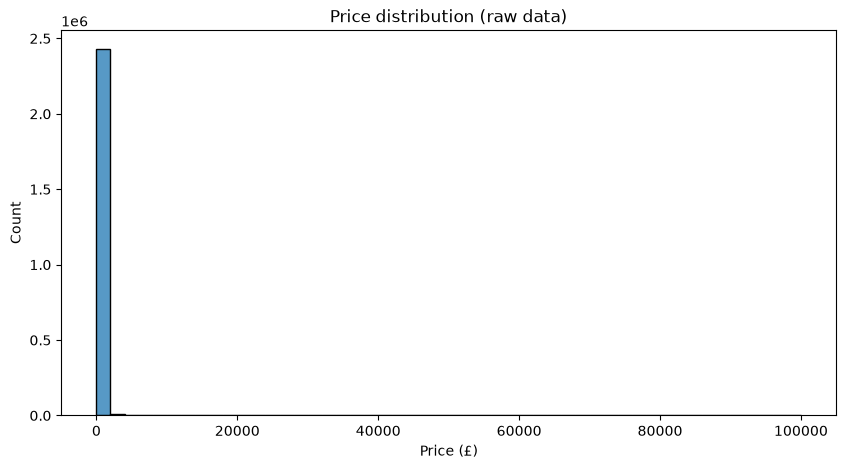

In [10]:
# i'm gonna draw 3 different histograms because the outliers are making the first one hard to read
# raw histogram: hard to read
plt.figure(figsize=(10, 5))
sns.histplot(df["price"], bins=50)
plt.title("Price distribution (raw data)")
plt.xlabel("Price (£)")
plt.show()


**Why the histogram is hard to read**: prices go up to £100,000, but 75% of the products cost less than £46. A few extreme values stretch the x axis, the bins become huge and almost every product falls in the first bar. It can be solved by zooming on the range where most products are, by removing or capping the outliers, or by using a log scale.


Products up to £100: 86.6%


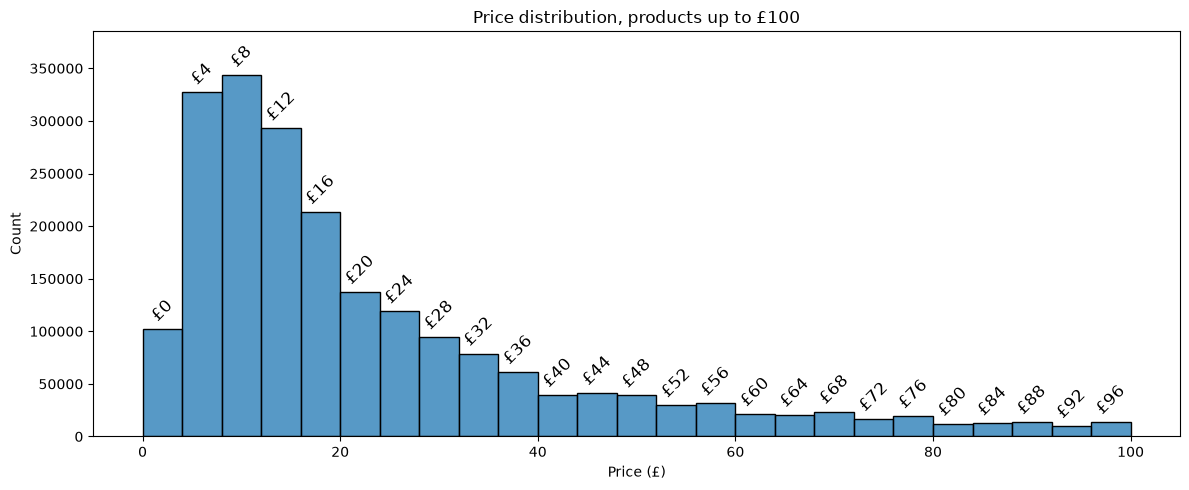

In [11]:
# solution 1: zoom on prices up to £100
share_below_100 = (df["price"] <= 100).mean() * 100
print(f"Products up to £100: {share_below_100:.1f}%")

fig, ax = plt.subplots(figsize=(12, 5))
sns.histplot(df.loc[df["price"] <= 100, "price"], bins=25, ax=ax)

# label on each bar = price at the left edge of the bar (empty bars get no label)
labels = [f"£{p.get_x():,.0f}" if p.get_height() > 0 else "" for p in ax.patches]
ax.bar_label(ax.containers[0], labels=labels, rotation=45, fontsize=12, padding=3)

ax.set_title("Price distribution, products up to £100")
ax.set_xlabel("Price (£)")
ax.margins(y=0.12)
plt.tight_layout()
plt.show()


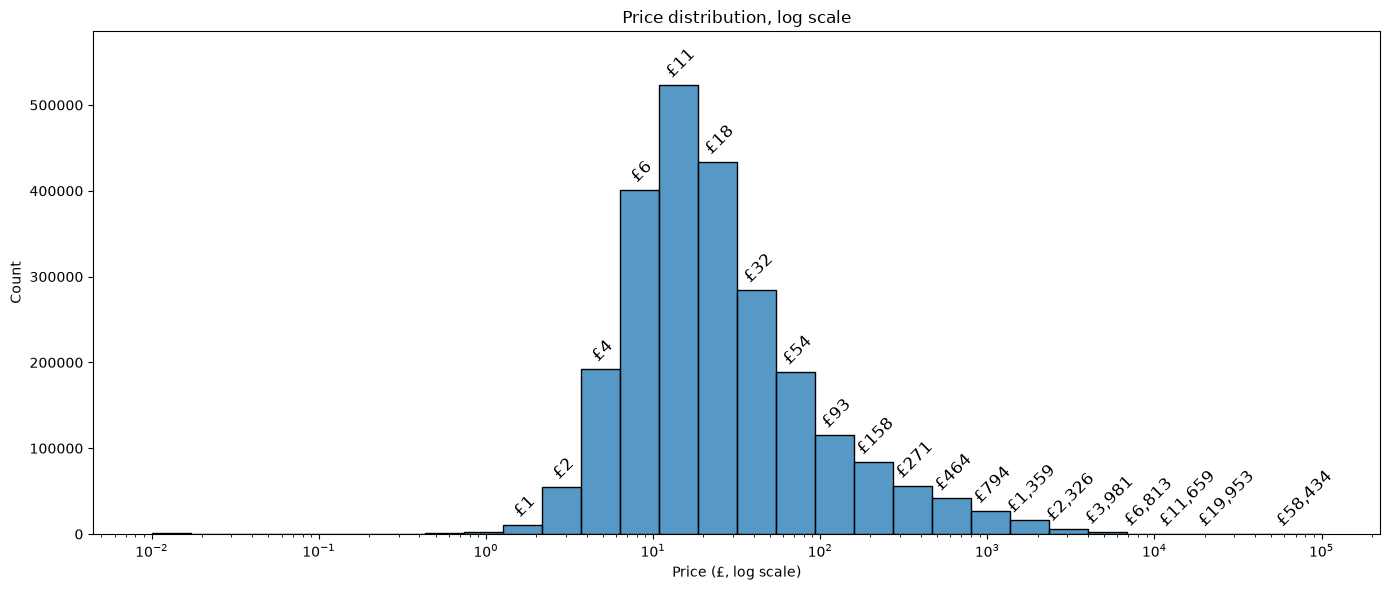

In [12]:
# solution 2: log scale (price = 0 is excluded because log(0) is undefined)
fig, ax = plt.subplots(figsize=(14, 6))
sns.histplot(df.loc[df["price"] > 0, "price"], bins=30, log_scale=True, ax=ax)

# label on each bar = price at the left edge of the bar (empty bars and prices below £1 get no label)
labels = [f"£{p.get_x():,.0f}" if p.get_height() > 0 and p.get_x() >= 1 else "" for p in ax.patches]
ax.bar_label(ax.containers[0], labels=labels, rotation=45, fontsize=12, padding=3)

ax.set_title("Price distribution, log scale")
ax.set_xlabel("Price (£, log scale)")
ax.margins(y=0.12)
plt.tight_layout()
plt.show()


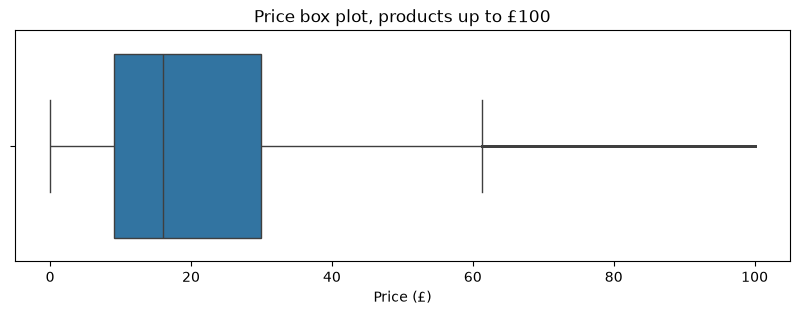

In [13]:
# box plot zoomed on prices up to £100 (same range as the histogram)
plt.figure(figsize=(10, 3))
sns.boxplot(x=df.loc[df["price"] <= 100, "price"], fliersize=1)
plt.title("Price box plot, products up to £100")
plt.xlabel("Price (£)")
plt.show()


In [14]:
upper_fence = q3 + 1.5 * price_iqr
n_outliers = (df["price"] > upper_fence).sum()
print(f"Upper fence: £{upper_fence:.2f} -> {n_outliers:,} outliers ({n_outliers / len(df) * 100:.1f}%)")

df.nlargest(5, "price")[["title", "category", "price"]]


Upper fence: £99.99 -> 327,688 outliers (13.4%)


,title,category,price
2008013,HB FBA Test Treadmill,Sports & Outdoors,100000.00
1987238,Générique L.A 350° - I5 11400F - RTX 3050 8G -...,Desktop PCs,77752.00
1905315,Abaodam decor christmas ornaments Desk Ornamen...,Garden Storage & Housing,24674.59
1408966,BM4445-FI1-01200R10-03-E03 Driver,Scanners & Accessories,23482.73
319555,HEDUSA Halloween 3D Holographic Fan 3D Hologra...,Projectors,22933.42


### Part 2 - Findings
- **Average vs typical price**: the mean is £89.24 but the median is £19.09 and the mode £9.99. A few very expensive listings pull the mean up, so the median is the honest "typical price".
- **Psychological price points**: the most common prices are £9.99, £12.99, £8.99, £7.99 and £14.99. Sellers cluster just below round numbers.
- **High dispersion**: the standard deviation (£345.61) is almost 4 times the mean (coefficient of variation 3.87) and the range goes from £0 to £100,000. Yet the IQR is only £36 (from £9.99 to £45.99): half of the market sits in a narrow band.
- **Where most products fall**: 75% cost less than £46 and 86.6% up to £100. The log-scale histogram shows a peak around £10-20 and a long right tail.
- **Outliers**: the 1.5 x IQR rule flags every product above £99.99, about 327,000 listings (13.4%). Some are real expensive goods, others look like errors or tests (the £100,000 "HB FBA Test Treadmill"), and 20 products cost £0. They should be checked before any pricing model.
- **Note**: the box plot is zoomed on prices up to £100, so its quartiles are computed on that subset only; the figures above refer to the whole dataset.


---
## Part 3: Unpacking Product Ratings

**Business Question**: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

### 1. Measures of Centrality
- Calculate the mean, median, and mode for the `rating` of products.
- How do customers generally rate products? Is there a common trend?

Products with `stars = 0` have no rating yet, so they are excluded from the analysis of the ratings. In this dataset the rating column is called `stars`.

In [15]:
zero_share = (df["stars"] == 0).mean() * 100
print(f"Products with stars = 0 (not rated, excluded): {zero_share:.1f}%")

rated = df.loc[df["stars"] > 0, "stars"]
print(f"Rated products used in the analysis: {len(rated):,}")

print(f"Mean:   {rated.mean():.2f}")
print(f"Median: {rated.median():.2f}")
print(f"Mode:   {rated.mode()[0]:.2f}")

Products with stars = 0 (not rated, excluded): 50.2%
Rated products used in the analysis: 1,218,010
Mean:   4.32
Median: 4.40
Mode:   4.50


### 2. Measures of Dispersion
- Determine the variance, standard deviation, and interquartile range for product `rating`.
- Are the ratings consistent, or is there a wide variation in customer feedback?

In [16]:
rating_var = rated.var()
rating_std = rated.std()
rating_iqr = rated.quantile(0.75) - rated.quantile(0.25)

print(f"Variance: {rating_var:.2f}")
print(f"Std dev:  {rating_std:.2f}")
print(f"IQR:      {rating_iqr:.2f}")

Variance: 0.31
Std dev:  0.56
IQR:      0.50


### 3. Shape of the Distribution
- Calculate the skewness and kurtosis for the `rating` column.
- Are the ratings normally distributed, or do they lean towards higher or lower values?

In [17]:
print(f"Skewness: {rated.skew():.2f}")
print(f"Kurtosis: {rated.kurt():.2f}")

Skewness: -2.38
Kurtosis: 9.78


### 4. Visualizations
- Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

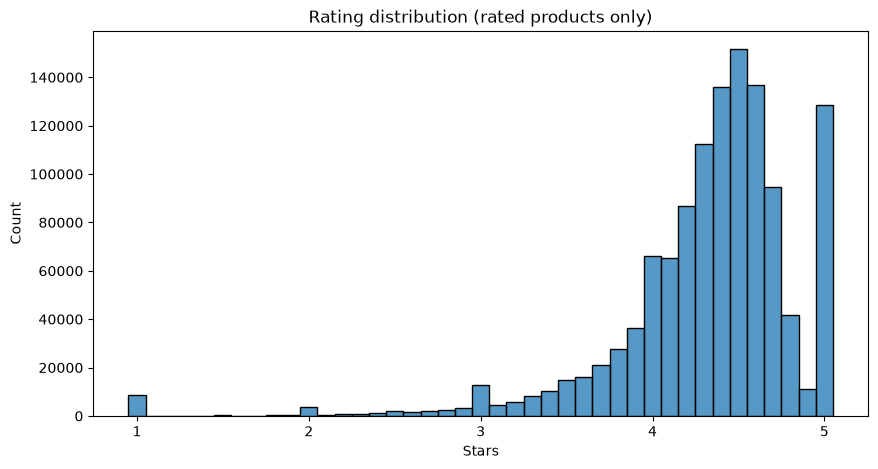

In [18]:
plt.figure(figsize=(10, 5))
sns.histplot(rated, binwidth=0.1, binrange=(0.95, 5.05))
plt.title("Rating distribution (rated products only)")
plt.xlabel("Stars")
plt.show()

### Part 3 - Findings
- **Half of the catalogue is unrated**: 50.2% of the listings have `stars = 0` (and no reviews). It means "no rating yet", so they were excluded; the analysis uses 1,218,010 rated products.
- **Customers rate very positively**: mean 4.32, median 4.40 and mode 4.50.
- **Ratings are consistent**: standard deviation 0.56, IQR 0.50 stars, variance 0.31.
- **Shape**: skewness -2.38 (strong left tail) and kurtosis 9.78 (heavy tails). Ratings pile up at 4-5 stars and a few poor products form a long tail on the left, so the distribution is far from normal. The most common rating is 4.5, with a second spike at 5.0.
- **Business reading**: a product rated below about 4.0 is clearly under the market, while 4.5 is only average. Getting the first reviews matters, since half of the listings have no social proof.
